# Team efficiency: offensive vs. defensive EPA/play

**EPA (expected points added)** measures how much each play changed a team's expected points. Averaging it per play is the best single measure of how efficient an offense or defense is.

We drop *garbage time* (win probability outside 10–90%) because teams play differently once a game is decided.

In [1]:
import sys
sys.path.insert(0, "../src")

import pandas as pd
from nfl_analytics import load_pbp, offensive_plays
pd.set_option("display.precision", 3)

SEASON = 2025  # change to 2026 for the current season to date

In [2]:
pbp = load_pbp(SEASON)
plays = offensive_plays(pbp)  # pass + run plays, regular season, WP 10-90%
print(f"{len(pbp):,} total plays -> {len(plays):,} analyzed plays")

48,771 total plays -> 26,707 analyzed plays


## Team EPA table
For defense, **lower** EPA allowed is better. `net_epa` = offense minus defense.

In [3]:
from nfl_analytics import team_epa

teams = team_epa(plays)
teams

,off_plays,off_epa,off_success,off_pass_rate,def_plays,def_epa,def_success,net_epa
team,,,,,,,,
LA,843,0.157,0.526,0.641,830,-0.054,0.412,0.211
NE,830,0.173,0.501,0.625,776,-0.006,0.466,0.179
SEA,725,0.051,0.479,0.572,753,-0.120,0.400,0.170
PHI,829,0.040,0.435,0.616,929,-0.107,0.423,0.147
GB,883,0.167,0.499,0.587,946,0.061,0.456,0.106
JAX,814,0.060,0.463,0.628,788,-0.044,0.444,0.104
DEN,913,0.044,0.434,0.643,959,-0.059,0.385,0.103
BUF,839,0.105,0.477,0.583,761,0.009,0.455,0.096
HOU,958,-0.036,0.412,0.615,859,-0.106,0.388,0.070


## The chart
The y-axis is inverted so **up and to the right is good** on both sides of the ball.

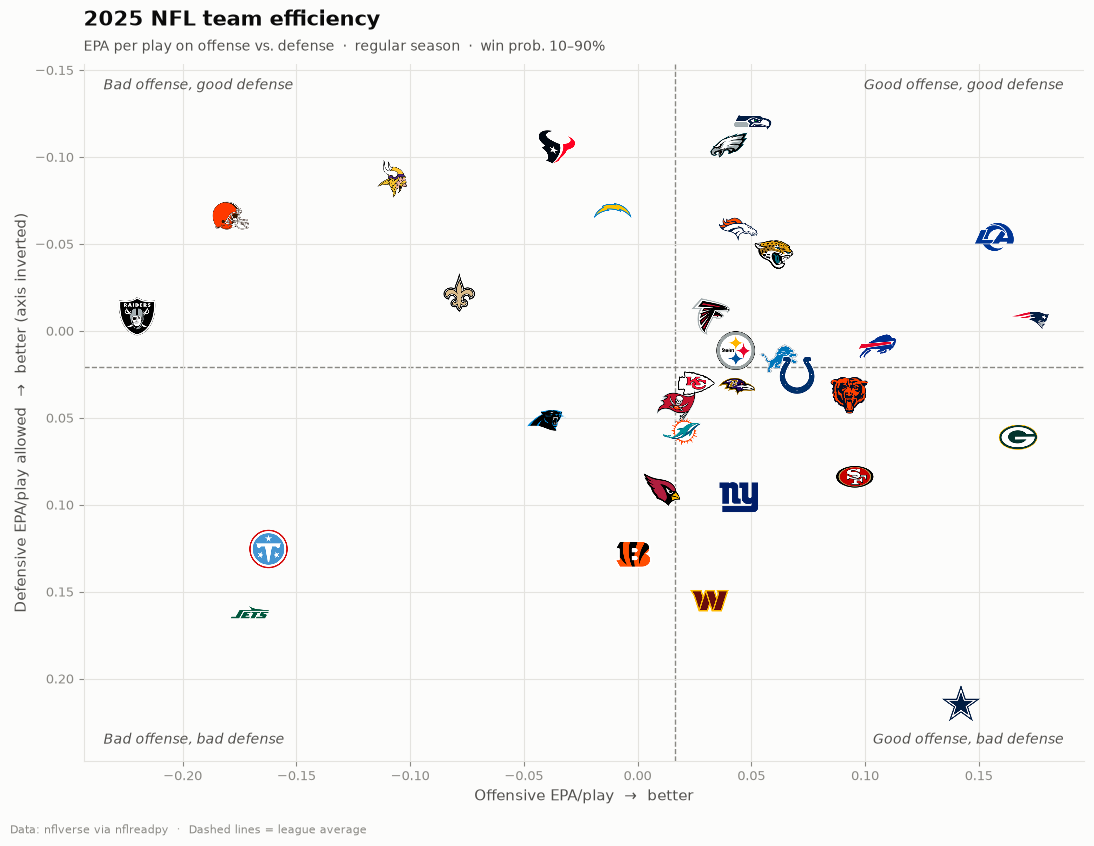

In [4]:
from nfl_analytics import plot_team_efficiency

fig, ax = plot_team_efficiency(
    teams,
    title=f"{SEASON} NFL team efficiency",
    subtitle="EPA per play on offense vs. defense  ·  regular season  ·  win prob. 10–90%",
)

## Passing vs. rushing efficiency
Split each offense into **dropbacks** (passes, sacks and scrambles) and **designed runs**. Both axes share a scale, so you can see that passing efficiency varies far more between teams than rushing does. Teams above the diagonal ran more efficiently than they passed.

In [5]:
from nfl_analytics import team_pass_rush_epa, plot_pass_vs_rush

split = team_pass_rush_epa(plays)
split

,pass_epa,rush_epa,pass_plays,rush_plays,pass_rate,pass_minus_rush
team,,,,,,
GB,0.344,-0.084,518,365,0.587,0.428
NE,0.321,-0.075,519,311,0.625,0.396
LA,0.237,0.014,540,303,0.641,0.223
DAL,0.230,-0.003,564,341,0.623,0.233
SF,0.177,-0.032,553,355,0.609,0.210
BUF,0.146,0.049,489,350,0.583,0.097
CHI,0.139,0.025,556,378,0.595,0.115
DET,0.139,-0.054,495,332,0.599,0.193
SEA,0.133,-0.060,415,310,0.572,0.192


Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


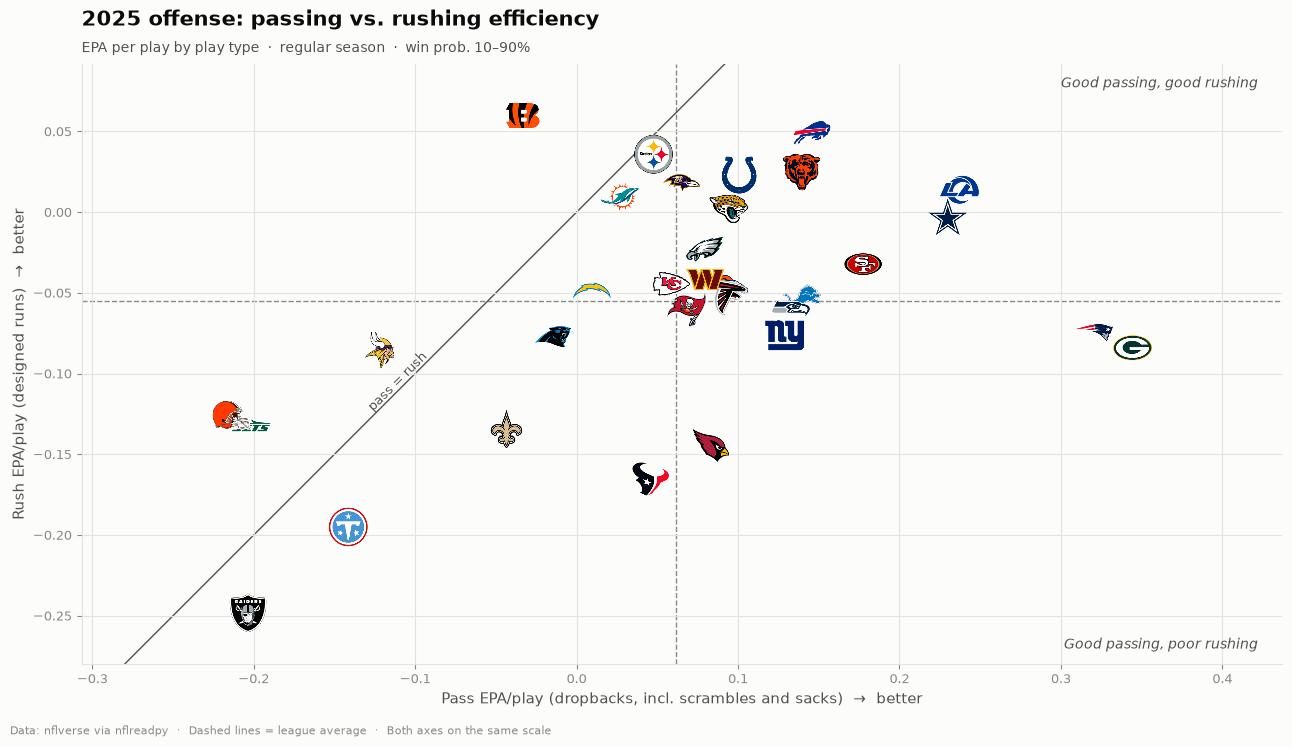

In [6]:
fig, ax = plot_pass_vs_rush(
    split,
    title=f"{SEASON} offense: passing vs. rushing efficiency",
    subtitle="EPA per play by play type  ·  regular season  ·  win prob. 10–90%",
)

In [7]:
print("League avg pass EPA/play:", round(split['pass_epa'].mean(), 3))
print("League avg rush EPA/play:", round(split['rush_epa'].mean(), 3))
print("Teams that ran better than they passed:", list(split[split['rush_epa'] > split['pass_epa']].index))
print("Corr(pass rate, pass EPA):", round(split['pass_rate'].corr(split['pass_epa']), 2))

League avg pass EPA/play: 0.062
League avg rush EPA/play: -0.055
Teams that ran better than they passed: ['CIN', 'MIN', 'NYJ', 'CLE']
Corr(pass rate, pass EPA): 0.03


## Pass/run tendencies by down
How often each team passes on 1st, 2nd and 3rd down. Raw pass rate mostly reflects situation: everyone passes on 3rd & long or when trailing late. So the color uses **pass rate over expected (PROE)**, the actual pass rate minus nflverse's `xpass` (expected pass probability given down, distance, field position, score and time). That isolates the play-caller's tendency.

Each cell shows the pass rate, then PROE in percentage points (★ = 95% interval excludes zero). 4th down is left out (too few go-for-it plays per team).

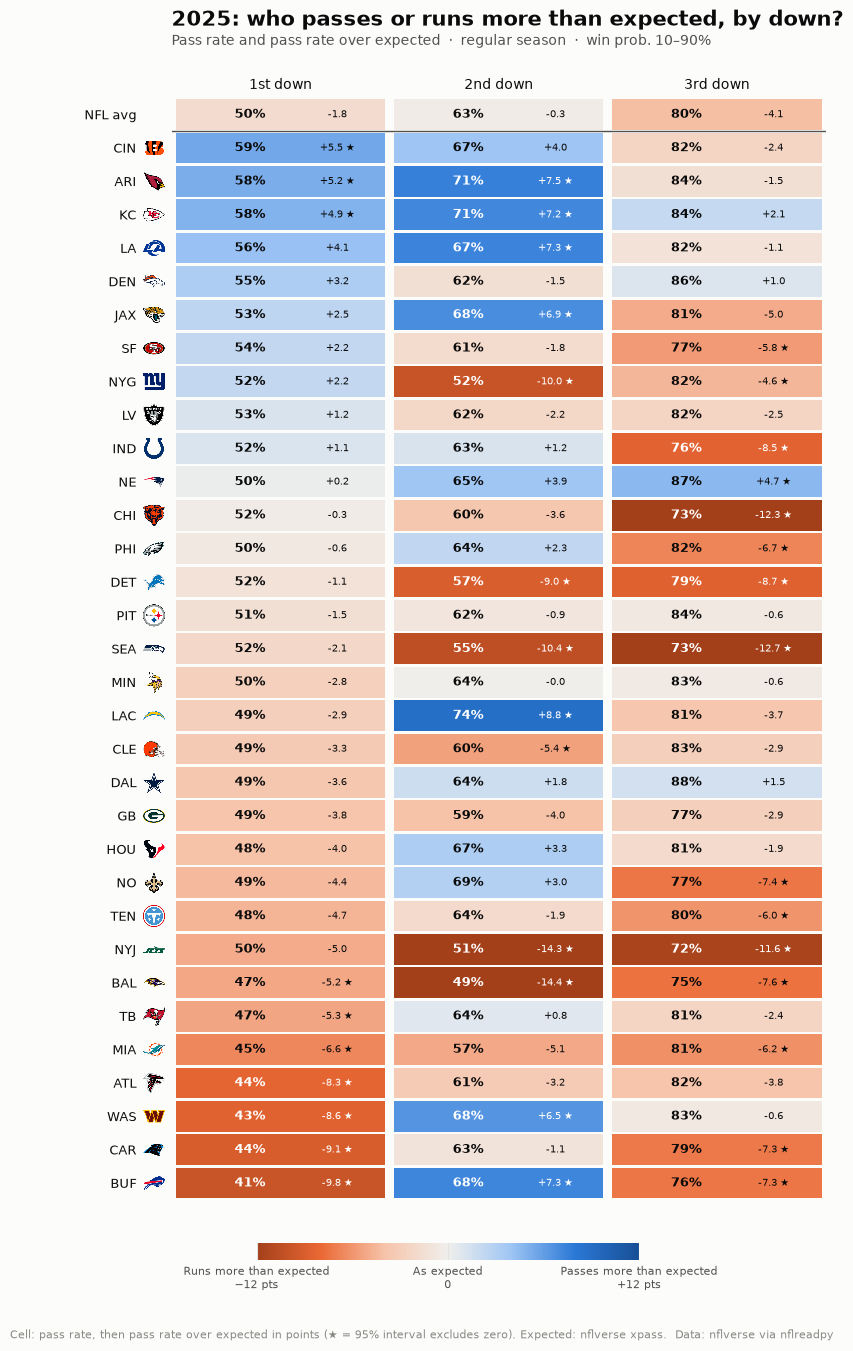

In [8]:
from nfl_analytics import pass_tendency_by_down, plot_pass_tendency_by_down

tendency = pass_tendency_by_down(plays)
fig, ax = plot_pass_tendency_by_down(
    tendency,
    title=f"{SEASON}: who passes or runs more than expected, by down?",
    subtitle="Pass rate and pass rate over expected  ·  regular season  ·  win prob. 10–90%",
)

In [9]:
# Are teams consistent across downs? Correlation of team PROE between downs.
wide = tendency[tendency["team"] != "NFL"].pivot(index="team", columns="situation", values="proe")
wide.corr().round(2)

situation,1st down,2nd down,3rd down
situation,,,
1st down,1.00,0.22,0.27
2nd down,0.22,1.00,0.53
3rd down,0.27,0.53,1.00


## Ideas to explore next
- Split 1st down by **field position** (own territory vs. red zone). Does running gain ground near the goal line?
- Compare **early-season vs. late-season** efficiency to see who improved.
- Check how well net EPA/play **predicts win totals** (`nflreadpy.load_schedules`).
- Re-run without the garbage-time filter (`offensive_plays(pbp, wp_range=None)`) and see who moves.